In [25]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"  # suppress verbose TensorFlow startup logs

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
tf.get_logger().setLevel("ERROR")

from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

tf.keras.utils.set_random_seed(42)
np.random.seed(42)
plt.style.use("seaborn-v0_8-whitegrid")
%matplotlib inline

print("Setup complete. You can start the experiment.")

Setup complete. You can start the experiment.


In [26]:
# Load and Normalize a Custom Synthetic 8x8 Dataset (Shapes: Cross, Ring, Stripe)

def generate_custom_dataset(num_samples=1500):
    np.random.seed(42)
    images = []
    labels = []

    for _ in range(num_samples):
        # Class 0: Cross
        # Class 1: Ring
        # Class 2: Stripe
        label = np.random.choice([0, 1, 2])
        img = np.zeros((8, 8), dtype="float32")

        # Base noise
        img += np.random.uniform(0.0, 0.15, (8, 8))

        if label == 0: # Cross
            img[3:5, :] += 0.7
            img[:, 3:5] += 0.7
        elif label == 1: # Ring
            img[1:7, 1] += 0.7
            img[1:7, 6] += 0.7
            img[1, 1:7] += 0.7
            img[6, 1:7] += 0.7
        elif label == 2: # Horizontal Stripes
            img[1:3, :] += 0.7
            img[5:7, :] += 0.7

        img = np.clip(img, 0.0, 1.0)
        images.append(img)
        labels.append(label)

    return np.array(images), np.array(labels)

X, y = generate_custom_dataset(num_samples=1800)

print("Custom Shape:", X.shape)
print("Custom Class counts (0: Cross, 1: Ring, 2: Stripe):\n", np.bincount(y))
print("Pixel value range after scaling: [{:.2f}, {:.2f}]".format(X.min(), X.max()))

Custom Shape: (1800, 8, 8)
Custom Class counts (0: Cross, 1: Ring, 2: Stripe):
 [579 627 594]
Pixel value range after scaling: [0.00, 1.00]


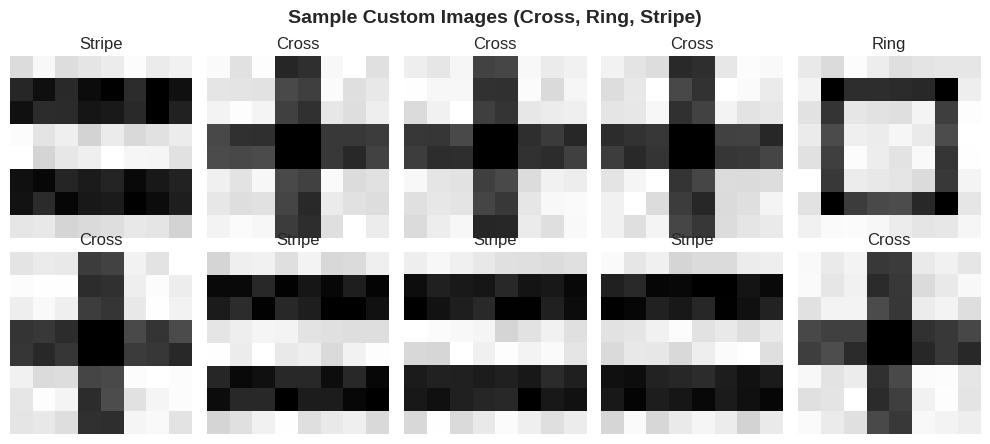

In [27]:
# Visualize Sample Custom Images

class_names = ["Cross", "Ring", "Stripe"]
fig, axes = plt.subplots(2, 5, figsize=(10, 4.5))

for i, ax in enumerate(axes.ravel()):
    ax.imshow(X[i], cmap="gray_r")
    ax.set_title(f"{class_names[y[i]]}")
    ax.axis("off")

plt.suptitle("Sample Custom Images (Cross, Ring, Stripe)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

In [28]:
# Train / Validation / Test Split (Updated for Custom 3-Class Dataset)

X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full,
    test_size=0.2,
    random_state=42,
    stratify=y_train_full,
)

# Add the channel dimension required by Conv2D: (samples, height, width, channels)
X_train_cnn = X_train[..., np.newaxis]
X_val_cnn = X_val[..., np.newaxis]
X_test_cnn = X_test[..., np.newaxis]

print("Train shape     :", X_train_cnn.shape)
print("Validation shape:", X_val_cnn.shape)
print("Test shape      :", X_test_cnn.shape)
print("Unique classes in test set:", np.unique(y_test))

Train shape     : (1152, 8, 8, 1)
Validation shape: (288, 8, 8, 1)
Test shape      : (360, 8, 8, 1)
Unique classes in test set: [0 1 2]


In [29]:
# Build the CNN for 3 classes

cnn_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(8, 8, 1)),
    tf.keras.layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(3, activation="softmax"),  # Updated to 3 classes
])

cnn_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

cnn_model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 32)       │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 4, 4, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 4, 4, 64)       │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 2, 2, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 35,459 (138.51 KB)

 Trainable params: 35,459 (138.51 KB)

 Non-trainable params: 0 (0.00 B)

In [30]:
# Train the CNN with Early Stopping

cnn_history = cnn_model.fit(
    X_train_cnn, y_train,
    validation_data=(X_val_cnn, y_val),
    epochs=30,
    batch_size=32,
    verbose=1,
    callbacks=[tf.keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True)],
)

print(f"CNN training completed after {len(cnn_history.history['loss'])} epochs.")

Epoch 1/30
36/36 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - accuracy: 0.9635 - loss: 0.4260 - val_accuracy: 1.0000 - val_loss: 0.0149
Epoch 2/30
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 1.0000 - loss: 0.0032 - val_accuracy: 1.0000 - val_loss: 7.3379e-04
Epoch 3/30
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 1.0000 - loss: 5.3327e-04 - val_accuracy: 1.0000 - val_loss: 4.1130e-04
Epoch 4/30
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 1.0000 - loss: 3.2797e-04 - val_accuracy: 1.0000 - val_loss: 2.6210e-04
Epoch 5/30
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 1.0000 - loss: 2.1295e-04 - val_accuracy: 1.0000 - val_loss: 1.7563e-04
Epoch 6/30
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 1.0000 - loss: 1.4674e-04 - val_accuracy: 1.0000 - val_loss: 1.2443e-04
Epoch 7/30
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 1.0000 - loss: 1.0573e-04 - val_accuracy: 1.0000 - val_loss: 9.1383e-05
Epoch 8/30
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 1.0000 - lo

In [31]:
# Evaluate the CNN on the Test Set for 3 Classes

cnn_test_prob = cnn_model.predict(X_test_cnn, verbose=0)
cnn_test_pred = np.argmax(cnn_test_prob, axis=1)

cnn_accuracy = accuracy_score(y_test, cnn_test_pred)
print(f"CNN Test Accuracy : {cnn_accuracy:.4f}")
print(classification_report(y_test, cnn_test_pred, target_names=class_names))

CNN Test Accuracy : 1.0000
              precision    recall  f1-score   support

       Cross       1.00      1.00      1.00       116
        Ring       1.00      1.00      1.00       125
      Stripe       1.00      1.00      1.00       119

    accuracy                           1.00       360
   macro avg       1.00      1.00      1.00       360
weighted avg       1.00      1.00      1.00       360



In [32]:
# Prepare Images for Transfer Learning (RGB, Resized to 96x96)

def resize_for_transfer(images):
    images_rgb = np.repeat(images[..., np.newaxis], 3, axis=-1)   # grayscale -> 3 channels
    images_resized = tf.image.resize(images_rgb, (96, 96)).numpy()  # match MobileNetV2 input size
    return images_resized

X_train_tl = resize_for_transfer(X_train)
X_val_tl = resize_for_transfer(X_val)
X_test_tl = resize_for_transfer(X_test)

print("Transfer learning input shape:", X_train_tl.shape)

Transfer learning input shape: (1152, 96, 96, 3)


In [33]:
# Build the Transfer Learning Model (Frozen MobileNetV2 + 3-Class Classifier Head)

base_model = tf.keras.applications.MobileNetV2(
    input_shape=(96, 96, 3),
    include_top=False,
    weights="imagenet",
)
base_model.trainable = False  # freeze the pretrained feature extractor

transfer_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(96, 96, 3)),
    tf.keras.layers.Lambda(tf.keras.applications.mobilenet_v2.preprocess_input),
    base_model,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(3, activation="softmax"),  # Updated to 3 classes
])

transfer_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

transfer_model.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lambda_2 (Lambda)               │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_96             │ (None, 3, 3, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 64)             │        81,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,340,163 (8.93 MB)

 Trainable params: 82,179 (321.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [34]:
# Train Only the Classifier Head (Early Stopping)

transfer_history = transfer_model.fit(
    X_train_tl, y_train,
    validation_data=(X_val_tl, y_val),
    epochs=10,
    batch_size=32,
    verbose=1,
    callbacks=[tf.keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True)],
)

print(f"Transfer learning training completed after {len(transfer_history.history['loss'])} epochs.")

Epoch 1/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 10s 168ms/step - accuracy: 0.3550 - loss: 1.1246 - val_accuracy: 0.3472 - val_loss: 1.0816
Epoch 2/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 6s 159ms/step - accuracy: 0.4392 - loss: 1.0692 - val_accuracy: 0.3472 - val_loss: 1.0305
Epoch 3/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 10s 150ms/step - accuracy: 0.5312 - loss: 1.0129 - val_accuracy: 0.6701 - val_loss: 0.9700
Epoch 4/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 5s 147ms/step - accuracy: 0.6042 - loss: 0.9575 - val_accuracy: 0.7639 - val_loss: 0.9075
Epoch 5/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 5s 142ms/step - accuracy: 0.6337 - loss: 0.8978 - val_accuracy: 1.0000 - val_loss: 0.8432
Epoch 6/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 5s 152ms/step - accuracy: 0.7899 - loss: 0.8305 - val_accuracy: 0.9583 - val_loss: 0.7771
Epoch 7/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 10s 154ms/step - accuracy: 0.8472 - loss: 0.7560 - val_accuracy: 0.7188 - val_loss: 0.7110
Epoch 8/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 5s 137ms/step - accuracy: 0.9149 - loss: 0.6795 - val_accuracy:

In [35]:
# Evaluate the Transfer Learning Model on the Test Set for 3 Classes

transfer_test_prob = transfer_model.predict(X_test_tl, verbose=0)
transfer_test_pred = np.argmax(transfer_test_prob, axis=1)

transfer_accuracy = accuracy_score(y_test, transfer_test_pred)
print(f"Transfer Learning Test Accuracy : {transfer_accuracy:.4f}")
print(classification_report(y_test, transfer_test_pred, target_names=class_names))

Transfer Learning Test Accuracy : 1.0000
              precision    recall  f1-score   support

       Cross       1.00      1.00      1.00       116
        Ring       1.00      1.00      1.00       125
      Stripe       1.00      1.00      1.00       119

    accuracy                           1.00       360
   macro avg       1.00      1.00      1.00       360
weighted avg       1.00      1.00      1.00       360



In [36]:
# Compare CNN vs Transfer Learning

comparison_df = pd.DataFrame([
    ["CNN (from scratch)", cnn_accuracy, len(cnn_history.history["loss"])],
    ["Transfer Learning (MobileNetV2)", transfer_accuracy, len(transfer_history.history["loss"])],
], columns=["Model", "Test Accuracy", "Epochs Trained"]).round(4)

comparison_df

,Model,Test Accuracy,Epochs Trained
0,CNN (from scratch),1.0,30
1,Transfer Learning (MobileNetV2),1.0,10


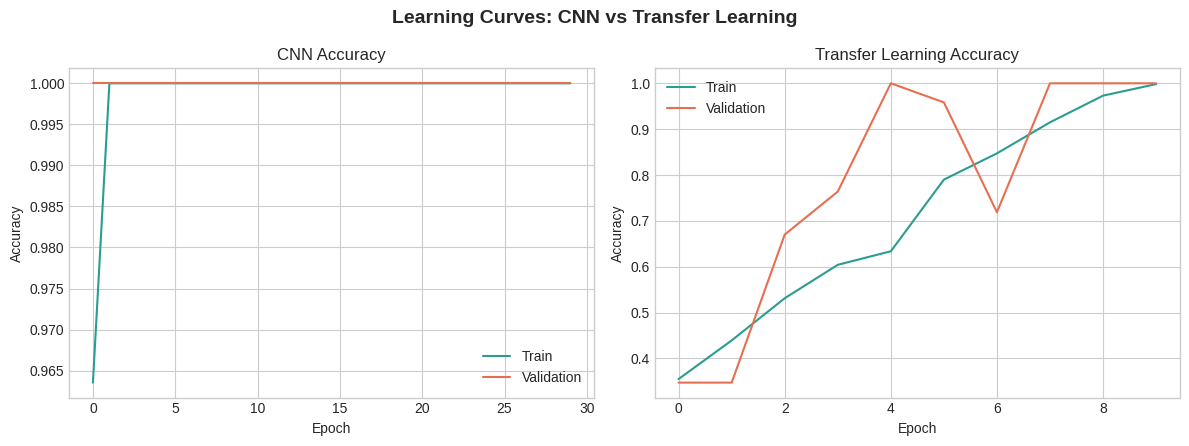

In [37]:
# Training vs Validation Accuracy: CNN vs Transfer Learning

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].plot(cnn_history.history["accuracy"], label="Train", color="#2a9d8f")
axes[0].plot(cnn_history.history["val_accuracy"], label="Validation", color="#e76f51")
axes[0].set_title("CNN Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].plot(transfer_history.history["accuracy"], label="Train", color="#2a9d8f")
axes[1].plot(transfer_history.history["val_accuracy"], label="Validation", color="#e76f51")
axes[1].set_title("Transfer Learning Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.suptitle("Learning Curves: CNN vs Transfer Learning", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

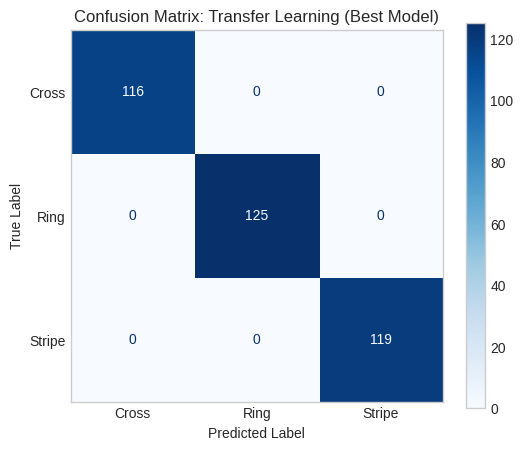

In [38]:
# Confusion Matrix for the Stronger Model (3 Classes)

if transfer_accuracy >= cnn_accuracy:
    best_name, best_pred = "Transfer Learning", transfer_test_pred
else:
    best_name, best_pred = "CNN", cnn_test_pred

cm = confusion_matrix(y_test, best_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)

fig, ax = plt.subplots(figsize=(6, 5))
disp.plot(cmap="Blues", ax=ax, colorbar=True, values_format="d")

plt.title(f"Confusion Matrix: {best_name} (Best Model)")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.grid(False)
plt.show()

Best Model             : Transfer Learning
Correctly classified   : 360 / 360
Misclassified           : 0 / 360


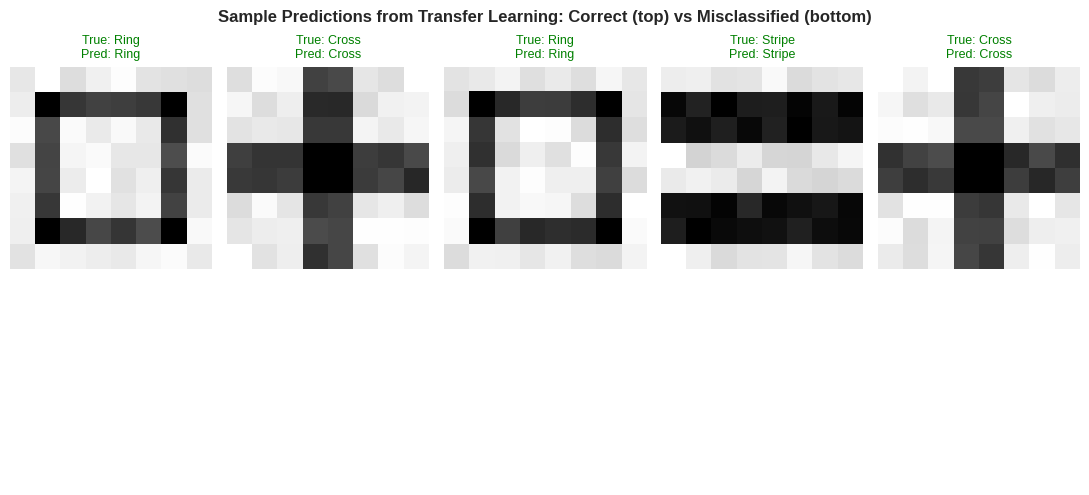

In [39]:
# Visualize Correct and Misclassified Predictions from the Best Model (3 Classes)

misclassified = np.where(best_pred != y_test)[0]
correct = np.where(best_pred == y_test)[0]

print(f"Best Model             : {best_name}")
print(f"Correctly classified   : {len(correct)} / {len(y_test)}")
print(f"Misclassified           : {len(misclassified)} / {len(y_test)}")

sample_correct = np.random.choice(correct, size=5, replace=False)
sample_wrong = misclassified[:5] if len(misclassified) >= 5 else misclassified

fig, axes = plt.subplots(2, 5, figsize=(11, 5))

for ax, idx in zip(axes[0], sample_correct):
    ax.imshow(X_test[idx], cmap="gray_r")
    ax.set_title(f"True: {class_names[y_test[idx]]}\nPred: {class_names[best_pred[idx]]}", fontsize=9, color="green")
    ax.axis("off")

for ax, idx in zip(axes[1], sample_wrong):
    ax.imshow(X_test[idx], cmap="gray_r")
    ax.set_title(f"True: {class_names[y_test[idx]]}\nPred: {class_names[best_pred[idx]]}", fontsize=9, color="red")
    ax.axis("off")

for ax in axes[1][len(sample_wrong):]:
    ax.axis("off")

plt.suptitle(f"Sample Predictions from {best_name}: Correct (top) vs Misclassified (bottom)",
             fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()